In [8]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import voronoi_polygons
from shapely.geometry import LineString, MultiPoint, box

from connectpt.routes_generator.data import load_instance
from connectpt.preprocess.connectivity_gdf import connectivity_gdf, map_polygons

In [9]:
instance_dir = ROOT / "datasets/instances/mumford0"
instance = load_instance("mumford0")
routes = instance.init_routes
xy = instance.tensors["node_locs"].numpy()

In [10]:
bounds = box(*(xy.min(0) - 1), *(xy.max(0) + 1))
cells = voronoi_polygons(MultiPoint(xy), extend_to=bounds)
polygons = gpd.GeoDataFrame(geometry=list(cells.geoms)).clip(bounds).reset_index(drop=True)

In [11]:
mapped = map_polygons(polygons, instance_dir)
result, full = connectivity_gdf(mapped, instance_dir, routes, agg="sum")
result.head()

,geometry,node,connectivity
0,"POLYGON ((13.33333 0.66667, 13.875 1.75, 14.25...",1,28.482616
1,"POLYGON ((16.5 2, 18 2.75, 18 0, 16.5 0, 16.5 2))",9,27.223320
2,"POLYGON ((10.25 4, 12.75 4, 13.875 1.75, 13.33...",24,25.193478
3,"POLYGON ((15.83333 5.16667, 18 4.625, 18 2.75,...",23,25.764431
4,"POLYGON ((14.05556 6.61111, 14.33333 6.66667, ...",14,20.225023


In [12]:
full.head()

,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,NaN,1.392955,1.509607,0.338975,0.089204,0.978500,0.082342,0.020586,0.201281,3.149588,...,0.808783,0.205855,1.264867,0.864593,2.781336,0.166514,0.434584,2.832114,1.772644,0.880604
1,1.199291,NaN,0.061442,0.033084,0.212288,0.274124,0.535250,0.673494,0.479716,1.727846,...,0.256400,0.322568,1.084679,1.493501,2.755416,2.908231,1.827491,1.543915,0.712485,0.781410
2,1.495242,0.070684,NaN,0.636158,0.849570,0.494789,0.462166,0.108745,0.369733,0.344359,...,0.061622,1.015859,1.458994,0.977798,1.719529,2.214771,0.208428,1.123244,1.250566,1.941097
3,0.289002,0.032761,0.547582,NaN,0.065523,0.723869,0.349844,0.442278,1.304212,0.914977,...,0.655226,1.151326,1.898206,1.759750,1.755070,2.190328,0.278081,1.777691,1.647426,0.772231
4,0.096439,0.266568,0.927300,0.083086,NaN,0.231454,0.138477,0.539070,0.830860,0.811078,...,0.367953,2.010880,1.910979,1.545500,0.261128,0.051434,1.345203,0.195846,1.440158,0.697329


Text(0.5, 1.0, 'Mumford0: connectivity C_i per polygon, min')

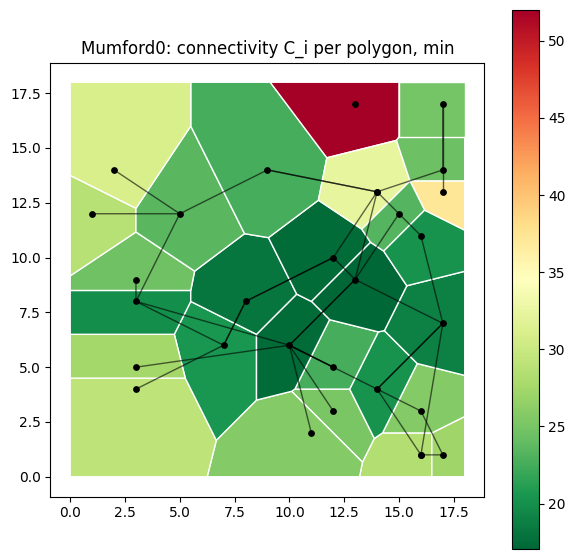

In [13]:
fig, ax = plt.subplots(figsize=(7, 7))
result.plot(column="connectivity", cmap="RdYlGn_r", legend=True, edgecolor="white", ax=ax,
            missing_kwds={"color": "lightgrey"})
lines = [LineString(xy[r[r >= 0]]) for r in routes[0].numpy()]
gpd.GeoSeries(lines).plot(ax=ax, color="black", linewidth=1, alpha=0.6)
ax.scatter(xy[:, 0], xy[:, 1], s=15, color="black")
ax.set_title("Mumford0: connectivity C_i per polygon, min")